# Stage 2 — SegFormer-B0 Pipeline (clean rebuild, tuna-masking fixes applied)

**Three fixes applied in this version, targeting Stage 2's masking of Stage 1-flagged tuna crops:**

1. **Lower detection threshold for Stage 1-flagged crops.** Raw `argmax` requires the anomaly
   class to win outright. Since Stage 1 already flagged the crop, a lower probability threshold
   (with a minimum pixel-count floor to reject noise) recovers faint-but-real detections without
   retraining.
2. **Merge nearby flagged regions before cropping.** The old connected-pipeline code cropped only
   the SINGLE LARGEST connected component. Visual review found real foam fields captured only as
   an edge fragment when the true disturbance was irregular/split. A small dilation before
   labeling fixes this.
3. **Crop-style training augmentation.** SegFormer was trained on full frames resized to 512x512,
   but at deployment it sees a small Stage-1-cropped region upscaled to 512x512 - a confirmed
   scale mismatch. Training now sometimes shows the model a simulated Stage-1-style crop of its
   own training images, closing this gap using data already on hand.

**Not included here (separate, Stage 1-side follow-up, out of scope for this notebook):**
excluding vessels/birds from Stage 1's flagged output. That's a Stage 1 architecture change, not
a Stage 2 fix - noted for a future pass, not implemented in this rebuild.

**Removed from this version:** the pure-SegFormer-only unseen-pool test, the full 25/26-image
visualization grids, the training-negative sanity check, and the exploratory flagged-no-mask
diagnostic dumps - all of that already did its job (finding these three fixes). What remains is
training, the core performance metrics, and the fixed connected pipeline with a before/after check.

In [1]:
# --- Cell 1: Imports and config ---
import json
import pickle
import random
from pathlib import Path

import cv2
import numpy as np
from PIL import Image, ImageDraw
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import SegformerForSemanticSegmentation
from skimage.segmentation import slic
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from scipy import ndimage
import matplotlib.pyplot as plt

# --- Paths: update to match your machine ---
PRAWN_IMG_DIR = Path(r"C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_02\prawn_annotation_training\images\default")
TUNA_IMG_DIR  = Path(r"C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_02\tuna_annotation_training\images\default")
NEGATIVE_DIR  = Path(r"C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_01\data\normal_sea\heldout_split")
UNSEEN_PRAWN_DIR = Path(r"C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_01\data\prawns")
UNSEEN_TUNA_DIR  = Path(r"C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_01\data\tuna")

PRAWN_T1_JSON = Path("prawn_instances_default_t1.json")
PRAWN_T2_JSON = Path("prawn_instances_default_t2.json")
TUNA_T1_JSON  = Path("tuna_instances_default_t1.json")
TUNA_T2_JSON  = Path("tuna_instances_default_t2.json")

STAGE1_CONFIG_PATH = Path("stage1_final_config.json")
STAGE1_BUCKET_REF_PATH = Path("stage1_bucket_ref.pkl")

with open(STAGE1_CONFIG_PATH) as f:
    stage1_config = json.load(f)
with open(STAGE1_BUCKET_REF_PATH, "rb") as f:
    stage1_bucket_ref = pickle.load(f)

IMG_SIZE = tuple(stage1_config["img_size"])
print(f"Stage 1 config loaded. IMG_SIZE={IMG_SIZE}, false_positive_rate={stage1_config['false_positive_rate']:.2%}")

PRAWN_IOU_CEILING = 0.5867
TUNA_IOU_CEILING = 0.7204

# --- Training config ---
N_NEGATIVES_TO_USE = 437
BATCH_SIZE = 4
NUM_EPOCHS = 30
LEARNING_RATE = 6e-5
SEGFORMER_CHECKPOINT = "nvidia/segformer-b0-finetuned-ade-512-512"
OUTPUT_DIR = Path("stage2_output")
OUTPUT_DIR.mkdir(exist_ok=True)

# --- Fix 3 config: crop-style training augmentation ---
CROP_AUGMENT_PROB = 0.5   # fraction of positive training samples shown as a simulated Stage-1-style crop
CROP_AUGMENT_PAD_RANGE = (10, 40)

# --- Fix 1 config: lower detection threshold on Stage-1-flagged crops ---
STAGE2_PROB_THRESHOLD = 0.35   # instead of the implicit 0.5 from argmax
STAGE2_MIN_MASK_PIXELS = 80    # floor so a lower threshold doesn't call noise "a detection"

# --- Fix 2 config: merge nearby flagged regions before cropping ---
STAGE1_DILATION_ITERS = 2

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

random.seed(42)
np.random.seed(42)

Stage 1 config loaded. IMG_SIZE=(512, 512), false_positive_rate=46.22%


In [2]:
# --- Cell 2: Load and merge the COCO annotation JSONs ---

def load_coco(path):
    with open(path) as f:
        return json.load(f)

def coco_to_records(coco, img_dir, dataset_name):
    img_by_id = {img["id"]: img for img in coco["images"]}
    segs_by_image = {img["id"]: [] for img in coco["images"]}
    for ann in coco["annotations"]:
        segs_by_image[ann["image_id"]].extend(ann["segmentation"])
    records = []
    for img_id, img in img_by_id.items():
        records.append({
            "path": img_dir / img["file_name"], "filename": img["file_name"],
            "width": img["width"], "height": img["height"],
            "segmentations": segs_by_image[img_id], "dataset": dataset_name,
        })
    return records

prawn_t1 = coco_to_records(load_coco(PRAWN_T1_JSON), PRAWN_IMG_DIR, "prawn")
prawn_t2 = coco_to_records(load_coco(PRAWN_T2_JSON), PRAWN_IMG_DIR, "prawn")
tuna_t1  = coco_to_records(load_coco(TUNA_T1_JSON), TUNA_IMG_DIR, "tuna")
tuna_t2  = coco_to_records(load_coco(TUNA_T2_JSON), TUNA_IMG_DIR, "tuna")

print(f"Prawn: {len(prawn_t1)} yours, {len(prawn_t2)} teammate overlap")
print(f"Tuna:  {len(tuna_t1)} yours, {len(tuna_t2)} teammate overlap")

missing = [r["path"] for r in (prawn_t1 + tuna_t1) if not r["path"].exists()]
print("All image files found on disk." if not missing else f"WARNING: {len(missing)} files missing, e.g. {missing[:3]}")

Prawn: 25 yours, 10 teammate overlap
Tuna:  26 yours, 10 teammate overlap
All image files found on disk.


In [3]:
# --- Cell 3: Reserve the double-annotation overlap for evaluation only ---

prawn_t2_filenames = {r["filename"] for r in prawn_t2}
tuna_t2_filenames = {r["filename"] for r in tuna_t2}

prawn_train_records = [r for r in prawn_t1 if r["filename"] not in prawn_t2_filenames]
tuna_train_records  = [r for r in tuna_t1 if r["filename"] not in tuna_t2_filenames]
prawn_eval_records = [r for r in prawn_t1 if r["filename"] in prawn_t2_filenames]
tuna_eval_records  = [r for r in tuna_t1 if r["filename"] in tuna_t2_filenames]

print(f"Prawn: {len(prawn_train_records)} train, {len(prawn_eval_records)} held-out eval")
print(f"Tuna:  {len(tuna_train_records)} train, {len(tuna_eval_records)} held-out eval")

Prawn: 15 train, 10 held-out eval
Tuna:  16 train, 10 held-out eval


In [4]:
# --- Cell 4: Negative ("no target") examples, reused from Stage 1's held-out split ---

negative_paths = list(NEGATIVE_DIR.glob("*.jpg")) or list(NEGATIVE_DIR.glob("*.png"))
if N_NEGATIVES_TO_USE < len(negative_paths):
    negative_paths = random.sample(negative_paths, N_NEGATIVES_TO_USE)

negative_records = []
for p in negative_paths:
    with Image.open(p) as im:
        w, h = im.size
    negative_records.append({"path": p, "filename": p.name, "width": w, "height": h,
                               "segmentations": [], "dataset": "negative"})

print(f"Negative training examples: {len(negative_records)}")

Negative training examples: 437


In [5]:
# --- Cell 5: Dataset class - now with crop-style augmentation (FIX 3) ---
# For positive (prawn/tuna) samples, with probability CROP_AUGMENT_PROB, the
# image+mask are cropped tightly around the annotated region (padded, like
# Stage 1's real crop) BEFORE resizing to IMG_SIZE - so the model sometimes
# trains on the same kind of small, upscaled crop it will see at deployment,
# not just full frames.

def polygons_to_mask(width, height, segmentations):
    mask = Image.new("L", (width, height), 0)
    draw = ImageDraw.Draw(mask)
    for seg in segmentations:
        points = list(zip(seg[0::2], seg[1::2]))
        draw.polygon(points, fill=1)
    return mask

def simulate_stage1_crop(img, mask, pad_range=CROP_AUGMENT_PAD_RANGE):
    mask_arr = np.array(mask)
    if mask_arr.sum() == 0:
        return img, mask
    ys, xs = np.where(mask_arr > 0)
    y0, y1, x0, x1 = ys.min(), ys.max(), xs.min(), xs.max()
    pad = random.randint(*pad_range)
    W, H = img.size
    x0p, y0p = max(0, x0 - pad), max(0, y0 - pad)
    x1p, y1p = min(W, x1 + pad), min(H, y1 + pad)
    return img.crop((x0p, y0p, x1p, y1p)), mask.crop((x0p, y0p, x1p, y1p))

class AnomalySegDataset(Dataset):
    def __init__(self, records, img_size=IMG_SIZE, augment=False, crop_augment=False):
        self.records = records
        self.img_size = img_size
        self.augment = augment
        self.crop_augment = crop_augment

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        r = self.records[idx]
        img = Image.open(r["path"]).convert("RGB")
        mask = polygons_to_mask(r["width"], r["height"], r["segmentations"])

        is_positive = len(r["segmentations"]) > 0
        if self.crop_augment and is_positive and random.random() < CROP_AUGMENT_PROB:
            img, mask = simulate_stage1_crop(img, mask)

        img = img.resize(self.img_size, Image.BILINEAR)
        mask = mask.resize(self.img_size, Image.NEAREST)

        if self.augment and random.random() < 0.5:
            img = img.transpose(Image.FLIP_LEFT_RIGHT)
            mask = mask.transpose(Image.FLIP_LEFT_RIGHT)

        img_arr = np.array(img, dtype=np.float32) / 255.0
        img_arr = (img_arr - IMAGENET_MEAN) / IMAGENET_STD
        img_arr = img_arr.transpose(2, 0, 1)
        mask_arr = np.array(mask, dtype=np.int64)

        return {"pixel_values": torch.from_numpy(img_arr), "labels": torch.from_numpy(mask_arr),
                "filename": r["filename"], "dataset": r["dataset"]}

In [6]:
# --- Cell 6: Build train/eval DataLoaders ---

train_records = prawn_train_records + tuna_train_records + negative_records
random.shuffle(train_records)

train_dataset = AnomalySegDataset(train_records, augment=True, crop_augment=True)
prawn_eval_dataset = AnomalySegDataset(prawn_eval_records, augment=False, crop_augment=False)
tuna_eval_dataset = AnomalySegDataset(tuna_eval_records, augment=False, crop_augment=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
prawn_eval_loader = DataLoader(prawn_eval_dataset, batch_size=1, shuffle=False, num_workers=0)
tuna_eval_loader = DataLoader(tuna_eval_dataset, batch_size=1, shuffle=False, num_workers=0)

print(f"Training set: {len(train_dataset)} images "
      f"({len(prawn_train_records)} prawn + {len(tuna_train_records)} tuna + {len(negative_records)} negative)")
print(f"Prawn eval (held out): {len(prawn_eval_dataset)}  |  Tuna eval (held out): {len(tuna_eval_dataset)}")
print(f"Crop augmentation: {CROP_AUGMENT_PROB:.0%} of positive samples per epoch, pad range {CROP_AUGMENT_PAD_RANGE}")

Training set: 468 images (15 prawn + 16 tuna + 437 negative)
Prawn eval (held out): 10  |  Tuna eval (held out): 10
Crop augmentation: 50% of positive samples per epoch, pad range (10, 40)


In [7]:
# --- Cell 7: Load SegFormer-B0 and adapt for binary segmentation ---

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = SegformerForSemanticSegmentation.from_pretrained(
    SEGFORMER_CHECKPOINT, num_labels=2,
    id2label={0: "background", 1: "anomaly"}, label2id={"background": 0, "anomaly": 1},
    ignore_mismatched_sizes=True,
)
model.to(device)
print(f"SegFormer-B0 total parameters: {sum(p.numel() for p in model.parameters()):,}")

Using device: cpu


[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([2, 256, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


SegFormer-B0 total parameters: 3,714,658


In [8]:
# --- Cell 8: Fine-tune SegFormer-B0 ---

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

model.train()
for epoch in range(NUM_EPOCHS):
    epoch_loss = 0.0
    for batch in train_loader:
        pixel_values = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)
        outputs = model(pixel_values=pixel_values)
        logits = F.interpolate(outputs.logits, size=labels.shape[-2:], mode="bilinear", align_corners=False)
        loss = F.cross_entropy(logits, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)
    print(f"Epoch {epoch + 1}/{NUM_EPOCHS} - avg loss: {avg_loss:.4f}")
    if (epoch + 1) % 10 == 0:
        ckpt_path = OUTPUT_DIR / f"segformer_b0_epoch{epoch + 1}.pt"
        torch.save(model.state_dict(), ckpt_path)
        print(f"  Checkpoint saved: {ckpt_path}")

torch.save(model.state_dict(), OUTPUT_DIR / "segformer_b0_final.pt")
print("\nTraining complete.")

Epoch 1/30 - avg loss: 0.4021
Epoch 2/30 - avg loss: 0.1719
Epoch 3/30 - avg loss: 0.0993
Epoch 4/30 - avg loss: 0.0688
Epoch 5/30 - avg loss: 0.0527
Epoch 6/30 - avg loss: 0.0435
Epoch 7/30 - avg loss: 0.0372
Epoch 8/30 - avg loss: 0.0343
Epoch 9/30 - avg loss: 0.0326
Epoch 10/30 - avg loss: 0.0246
  Checkpoint saved: stage2_output\segformer_b0_epoch10.pt
Epoch 11/30 - avg loss: 0.0246
Epoch 12/30 - avg loss: 0.0306
Epoch 13/30 - avg loss: 0.0234
Epoch 14/30 - avg loss: 0.0230
Epoch 15/30 - avg loss: 0.0215
Epoch 16/30 - avg loss: 0.0194
Epoch 17/30 - avg loss: 0.0180
Epoch 18/30 - avg loss: 0.0164
Epoch 19/30 - avg loss: 0.0180
Epoch 20/30 - avg loss: 0.0189
  Checkpoint saved: stage2_output\segformer_b0_epoch20.pt
Epoch 21/30 - avg loss: 0.0164
Epoch 22/30 - avg loss: 0.0169
Epoch 23/30 - avg loss: 0.0149
Epoch 24/30 - avg loss: 0.0152
Epoch 25/30 - avg loss: 0.0150
Epoch 26/30 - avg loss: 0.0116
Epoch 27/30 - avg loss: 0.0404
Epoch 28/30 - avg loss: 0.0183
Epoch 29/30 - avg loss: 0

In [9]:
# --- Cell 9: PERFORMANCE METRIC - pick the best checkpoint on held-out eval ---

def compute_iou_binary(pred_mask, true_mask):
    pred, true = pred_mask.astype(bool), true_mask.astype(bool)
    union = np.logical_or(pred, true).sum()
    return None if union == 0 else np.logical_and(pred, true).sum() / union

def evaluate_silent(loader):
    model.eval()
    ious = []
    with torch.no_grad():
        for batch in loader:
            pixel_values = batch["pixel_values"].to(device)
            labels = batch["labels"].numpy()[0]
            outputs = model(pixel_values=pixel_values)
            logits = F.interpolate(outputs.logits, size=labels.shape, mode="bilinear", align_corners=False)
            pred = logits.argmax(dim=1).cpu().numpy()[0]
            iou = compute_iou_binary(pred, labels)
            if iou is not None:
                ious.append(iou)
    return float(np.mean(ious)) if ious else 0.0

checkpoint_paths = sorted(OUTPUT_DIR.glob("segformer_b0_epoch*.pt"))
checkpoint_results = []
for ckpt_path in checkpoint_paths:
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    model.to(device)
    prawn_iou = evaluate_silent(prawn_eval_loader)
    tuna_iou = evaluate_silent(tuna_eval_loader)
    checkpoint_results.append((ckpt_path.name, prawn_iou, tuna_iou))
    print(f"{ckpt_path.name}: prawn IoU={prawn_iou:.2%}, tuna IoU={tuna_iou:.2%}")

best_checkpoint = max(checkpoint_results, key=lambda r: (r[1] + r[2]) / 2)
print(f"\nBest checkpoint: {best_checkpoint[0]} (prawn={best_checkpoint[1]:.2%}, tuna={best_checkpoint[2]:.2%})")
model.load_state_dict(torch.load(OUTPUT_DIR / best_checkpoint[0], map_location=device))
model.to(device)

prawn_model_iou, tuna_model_iou = best_checkpoint[1], best_checkpoint[2]

segformer_b0_epoch10.pt: prawn IoU=28.63%, tuna IoU=72.79%
segformer_b0_epoch20.pt: prawn IoU=47.41%, tuna IoU=76.16%
segformer_b0_epoch30.pt: prawn IoU=38.38%, tuna IoU=77.08%

Best checkpoint: segformer_b0_epoch20.pt (prawn=47.41%, tuna=76.16%)


In [10]:
# --- Cell 10: PERFORMANCE METRIC - score against human-agreement ceilings ---

print(f"Prawn model IoU: {prawn_model_iou:.2%}  (human ceiling: {PRAWN_IOU_CEILING:.2%})")
if prawn_model_iou > PRAWN_IOU_CEILING:
    print("  NOTE: exceeds human ceiling - double-check rather than accept at face value.")

print(f"Tuna model IoU: {tuna_model_iou:.2%}  (human ceiling: {TUNA_IOU_CEILING:.2%})")
if tuna_model_iou > TUNA_IOU_CEILING:
    print("  NOTE: exceeds human ceiling - double-check rather than accept at face value.")

summary = {
    "segformer_checkpoint": SEGFORMER_CHECKPOINT, "best_checkpoint": best_checkpoint[0],
    "num_epochs": NUM_EPOCHS, "crop_augment_prob": CROP_AUGMENT_PROB,
    "n_train_images": len(train_dataset), "n_prawn_train": len(prawn_train_records),
    "n_tuna_train": len(tuna_train_records), "n_negative_train": len(negative_records),
    "prawn_model_iou": prawn_model_iou, "prawn_human_ceiling": PRAWN_IOU_CEILING,
    "tuna_model_iou": tuna_model_iou, "tuna_human_ceiling": TUNA_IOU_CEILING,
}
print(json.dumps(summary, indent=2))
with open(OUTPUT_DIR / "stage2_scored_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

Prawn model IoU: 47.41%  (human ceiling: 58.67%)
Tuna model IoU: 76.16%  (human ceiling: 72.04%)
  NOTE: exceeds human ceiling - double-check rather than accept at face value.
{
  "segformer_checkpoint": "nvidia/segformer-b0-finetuned-ade-512-512",
  "best_checkpoint": "segformer_b0_epoch20.pt",
  "num_epochs": 30,
  "crop_augment_prob": 0.5,
  "n_train_images": 468,
  "n_prawn_train": 15,
  "n_tuna_train": 16,
  "n_negative_train": 437,
  "prawn_model_iou": 0.47409655643009135,
  "prawn_human_ceiling": 0.5867,
  "tuna_model_iou": 0.7616344888295179,
  "tuna_human_ceiling": 0.7204
}


## Per-image performance on the 10+10 held-out test images

Cells 9-10 above give the AGGREGATE IoU across all 10 prawn and all 10 tuna held-out images -
useful as one headline number, but it hides which specific images the model handled well or
badly. This section breaks it down per image: the exact IoU for each of the 20 test images, plus
a visual (original / ground truth / prediction) for every one of them.

Uses the already-loaded best checkpoint (`model`, selected in Cell 9) and the existing
`prawn_eval_dataset` / `tuna_eval_dataset` (built in Cell 6) - no retraining or reloading needed.

In [11]:
# --- Per-image evaluation + visualization function ---

def evaluate_per_image(dataset, label, ceiling):
    model.eval()
    results = []
    with torch.no_grad():
        for i in range(len(dataset)):
            sample = dataset[i]
            pixel_values = sample["pixel_values"].unsqueeze(0).to(device)
            labels = sample["labels"].numpy()

            outputs = model(pixel_values=pixel_values)
            logits = F.interpolate(outputs.logits, size=labels.shape, mode="bilinear", align_corners=False)
            pred = logits.argmax(dim=1).cpu().numpy()[0]

            iou = compute_iou_binary(pred, labels)
            results.append({"filename": sample["filename"], "iou": iou, "pred": pred, "labels": labels,
                              "pixel_values": sample["pixel_values"]})

    print(f"{'filename':<45} | {'IoU':>8}")
    for r in sorted(results, key=lambda r: -(r["iou"] or 0)):
        iou_str = f"{r['iou']:.4f}" if r["iou"] is not None else "N/A"
        print(f"{r['filename']:<45} | {iou_str:>8}")

    valid_ious = [r["iou"] for r in results if r["iou"] is not None]
    print(f"\n{label} - mean: {np.mean(valid_ious):.2%}  |  min: {min(valid_ious):.2%}  |  "
          f"max: {max(valid_ious):.2%}  |  ceiling: {ceiling:.2%}")
    return results

def visualize_per_image(results, label):
    n = len(results)
    fig, axes = plt.subplots(n, 3, figsize=(9, n * 3))
    axes = np.atleast_2d(axes)

    for i, r in enumerate(results):
        img_display = r["pixel_values"].numpy().transpose(1, 2, 0)
        img_display = (img_display * IMAGENET_STD + IMAGENET_MEAN).clip(0, 1)

        axes[i, 0].imshow(img_display)
        axes[i, 0].set_title(r["filename"][:24], fontsize=7)
        axes[i, 0].axis("off")

        axes[i, 1].imshow(r["labels"], cmap="gray")
        axes[i, 1].set_title("Ground truth", fontsize=7)
        axes[i, 1].axis("off")

        axes[i, 2].imshow(r["pred"], cmap="gray")
        iou_str = f"{r['iou']:.2%}" if r["iou"] is not None else "N/A"
        axes[i, 2].set_title(f"Prediction (IoU={iou_str})", fontsize=7)
        axes[i, 2].axis("off")

    plt.suptitle(f"{label}: original / ground truth / prediction, per held-out image", y=1.0)
    plt.tight_layout()
    plt.show()

filename                                      |      IoU
IMG-20260227-WA0007.jpg                       |   0.8638
IMG-20260307-WA0076.jpg                       |   0.8472
IMG-20260227-WA0036.jpg                       |   0.7187
IMG-20260227-WA0013.jpg                       |   0.6421
IMG-20260227-WA0041.jpg                       |   0.5183
IMG-20260227-WA0042.jpg                       |   0.5004
IMG-20260307-WA0047.jpg                       |   0.4500
IMG-20260227-WA0012.jpg                       |   0.2004
IMG-20260227-WA0002.jpg                       |   0.0000
IMG-20260307-WA0005.jpg                       |   0.0000

Prawn - mean: 47.41%  |  min: 0.00%  |  max: 86.38%  |  ceiling: 58.67%


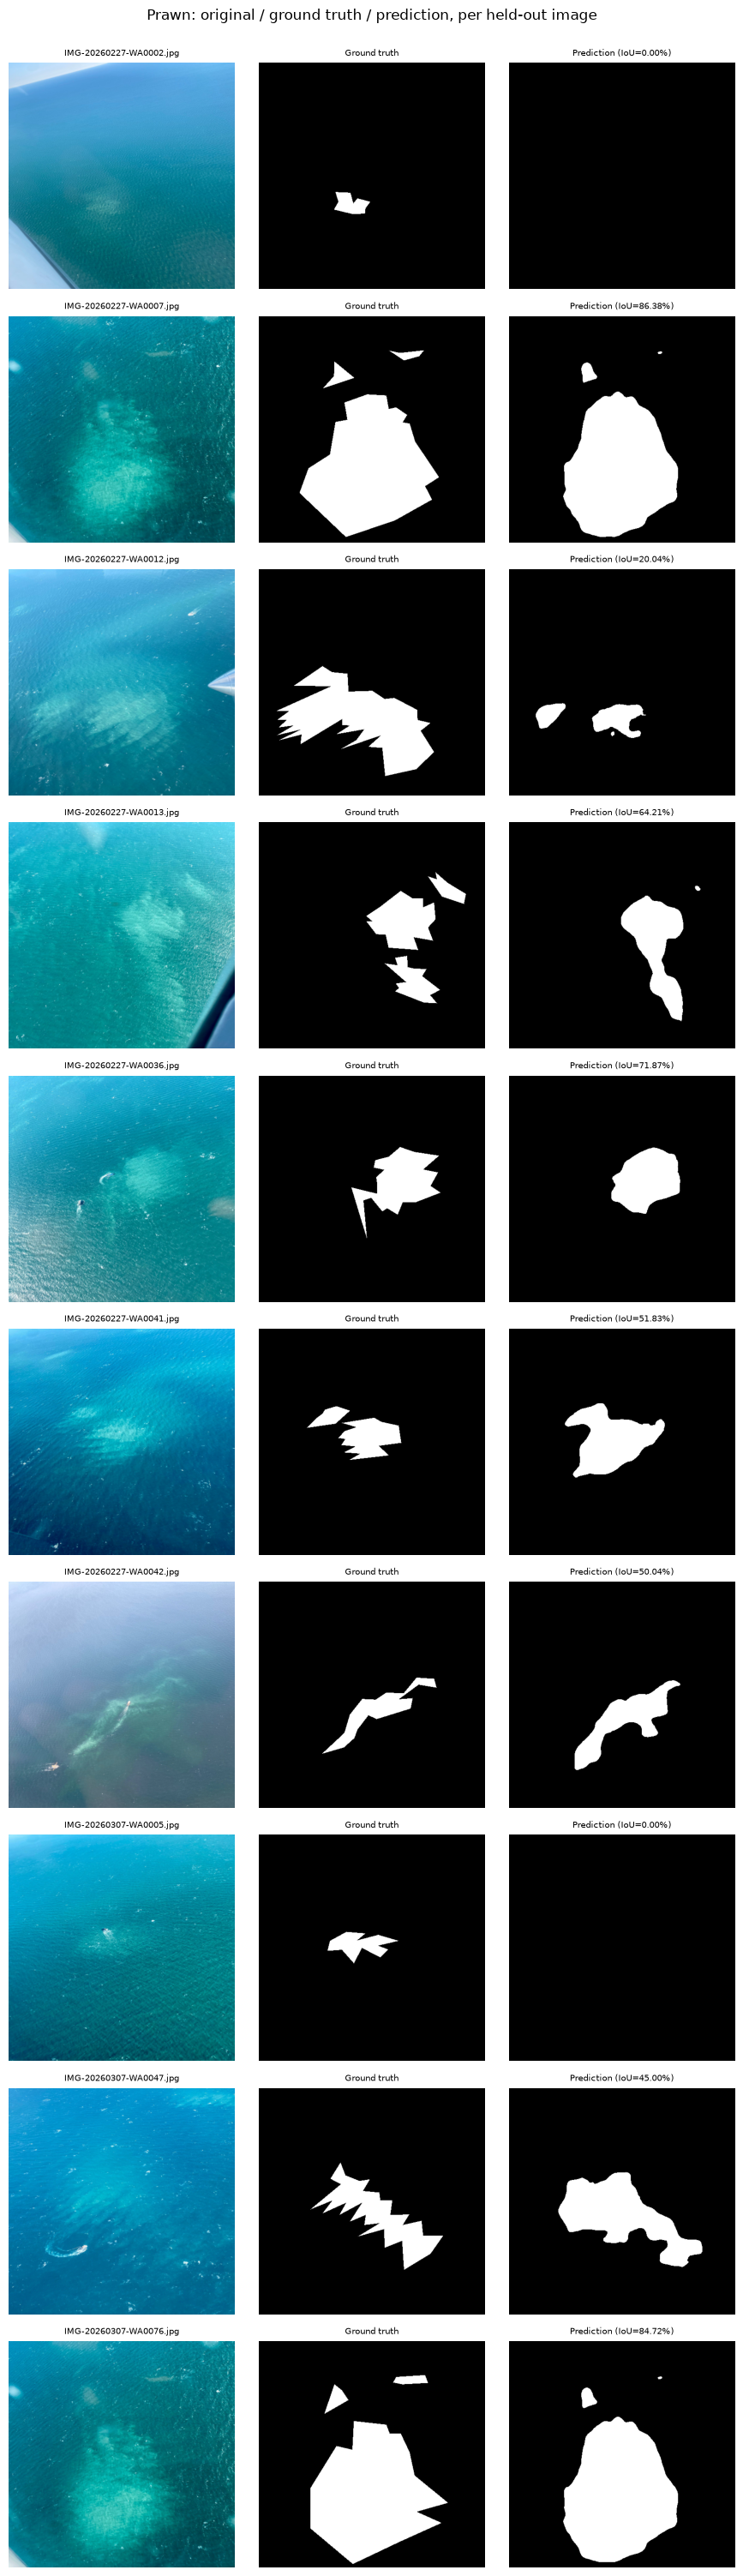

In [12]:
# --- Prawn: all 10 held-out test images ---
prawn_per_image_results = evaluate_per_image(prawn_eval_dataset, "Prawn", PRAWN_IOU_CEILING)
visualize_per_image(prawn_per_image_results, "Prawn")

filename                                      |      IoU
flipped_16_png.rf.ef84f116359c6c579db24fc63daca28a.jpg |   0.8504
flipped_17_png.rf.9f79c526188abb49b267ac462e3bd989.jpg |   0.8287
flipped_12_png.rf.e8f1a65733e71900ba8396a0d4f50ce4.jpg |   0.8186
flipped_3_png.rf.5cff8da197ae218d3f49b51484af7a84.jpg |   0.7951
flipped_15_png.rf.6c23fd8f1ddabcafc690344d1a2d496f.jpg |   0.7840
flipped_4_png.rf.91bc65804c9294689f828dd10426eb58.jpg |   0.7735
flipped_10_png.rf.f1da2f53b380dfb738b2b44b4b6d9420.jpg |   0.7724
flipped_14_png.rf.64ee61bbacfc4082035b225e5d13cf67.jpg |   0.7719
flipped_8_png.rf.b09f11bdfd4ddda496def9069e97dbcb.jpg |   0.6706
flipped_13_png.rf.2f8ab9180153a8f59b6f0a88ad7f7f0b.jpg |   0.5511

Tuna - mean: 76.16%  |  min: 55.11%  |  max: 85.04%  |  ceiling: 72.04%


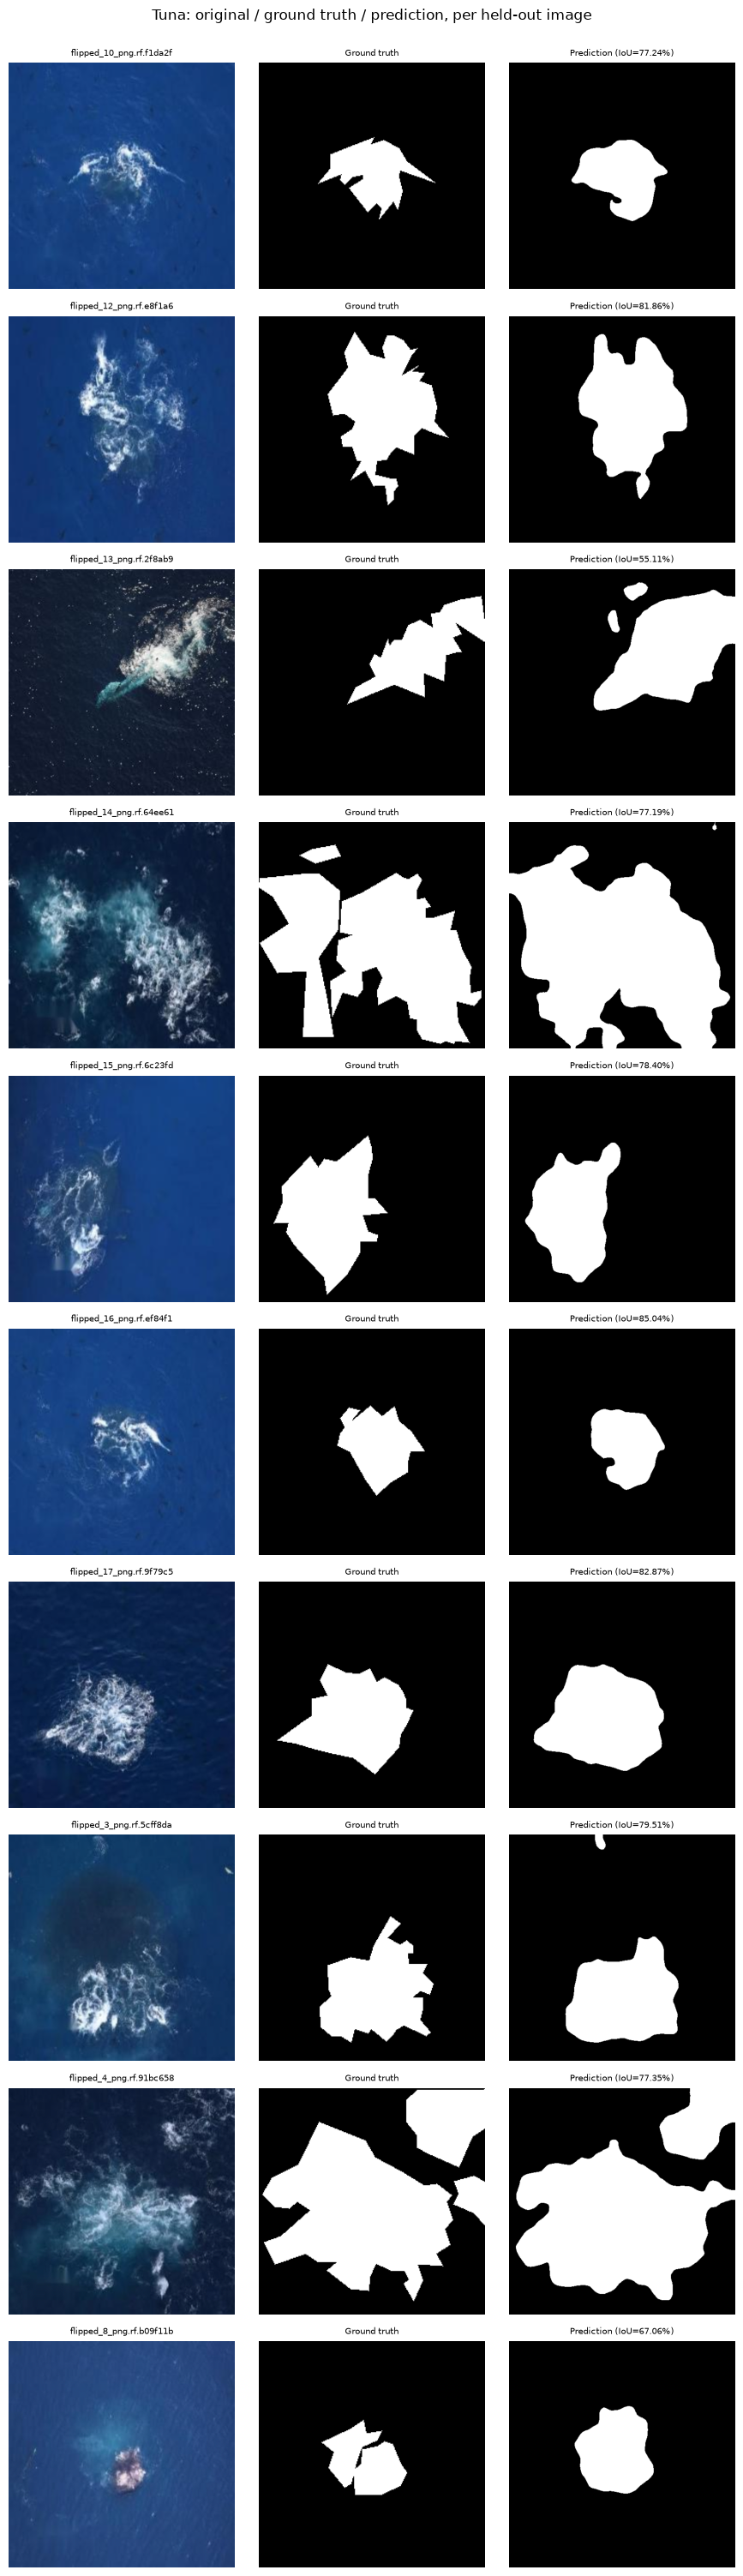

In [13]:
# --- Tuna: all 10 held-out test images ---
tuna_per_image_results = evaluate_per_image(tuna_eval_dataset, "Tuna", TUNA_IOU_CEILING)
visualize_per_image(tuna_per_image_results, "Tuna")

## Connected pipeline (Stage 1 -> Stage 2 on the whole frame), with Fixes 1 and 2 applied

Ports Stage 1's actual detector (texture rule OR local-brightness rule) from the saved config,
**now with region-merging (Fix 2)** before cropping, and scores Stage 2 crops with a **lowered,
floor-protected threshold (Fix 1)** instead of raw argmax.

In [14]:
# --- Cell 11: Ported Stage 1 detector, with Fix 2 (region merging via dilation) ---

S1_N_SEGMENTS = stage1_config["n_segments"]
S1_COMPACTNESS = stage1_config["compactness"]
S1_GLCM_LEVELS = stage1_config["glcm_levels"]
S1_Z_THRESH = stage1_config["z_thresh"]
S1_GLINT_THRESH = stage1_config["glint_thresh"]
S1_MIN_COMPONENT_AREA_PX = stage1_config["min_component_area_px"]
S1_MIN_FEATURES_FLAGGED = stage1_config["min_features_flagged"]
S1_BUCKET_EDGES = np.array(stage1_config["bucket_edges"])
S1_LOCAL_Z_THRESH = stage1_config.get("local_z_thresh", 999)
S1_MIN_AREA_LOCAL = stage1_config.get("min_area_local", 999999999)
FEATURE_KEYS = ["contrast_L", "homogeneity_L", "energy_L", "contrast_a", "lbp_var"]

def suppress_glint(img_bgr, thresh=S1_GLINT_THRESH, dilate_iter=2):
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    L = lab[:, :, 0]
    glint_mask = (L > thresh).astype(np.uint8)
    kernel = np.ones((5, 5), np.uint8)
    glint_mask = cv2.dilate(glint_mask, kernel, iterations=dilate_iter)
    return cv2.morphologyEx(glint_mask, cv2.MORPH_CLOSE, kernel)

def preprocess_image_s1(path, glint_thresh=S1_GLINT_THRESH):
    img_bgr = cv2.resize(cv2.imread(str(path)), IMG_SIZE)
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    glint_mask = suppress_glint(img_bgr, glint_thresh)
    rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    return lab, glint_mask, rgb

def quantize_s1(patch, levels=S1_GLCM_LEVELS):
    return (patch.astype(np.float32) / 256 * levels).astype(np.uint8)

def glcm_props_s1(patch_q, levels=S1_GLCM_LEVELS):
    glcm = graycomatrix(patch_q, distances=[1], angles=[0], levels=levels, symmetric=True, normed=True)
    return (float(graycoprops(glcm, 'contrast')[0, 0]), float(graycoprops(glcm, 'homogeneity')[0, 0]), float(graycoprops(glcm, 'energy')[0, 0]))

def extract_superpixel_features_s1(img_lab, glint_mask, n_segments=S1_N_SEGMENTS, compactness=S1_COMPACTNESS):
    L_channel, a_channel = img_lab[:, :, 0], img_lab[:, :, 1]
    segments = slic(img_lab, n_segments=n_segments, compactness=compactness, start_label=1)
    objects = ndimage.find_objects(segments)
    features = []
    for seg_id, bbox in enumerate(objects, start=1):
        if bbox is None:
            continue
        y_slice, x_slice = bbox
        local_mask = segments[y_slice, x_slice] == seg_id
        if glint_mask[y_slice, x_slice][local_mask].mean() > 0.5:
            continue
        patch_L, patch_a = L_channel[y_slice, x_slice], a_channel[y_slice, x_slice]
        if patch_L.shape[0] < 2 or patch_L.shape[1] < 2:
            continue
        contrast_L, homogeneity_L, energy_L = glcm_props_s1(quantize_s1(patch_L))
        contrast_a, _, _ = glcm_props_s1(quantize_s1(patch_a))
        lbp_var = float(np.var(local_binary_pattern(patch_L, P=8, R=1, method='uniform')))
        features.append({"seg_id": int(seg_id), "contrast_L": contrast_L, "homogeneity_L": homogeneity_L,
                          "energy_L": energy_L, "contrast_a": contrast_a, "lbp_var": lbp_var, "mean_L": float(patch_L.mean())})
    return segments, features

def image_sea_state_score(img_lab, glint_mask):
    L = img_lab[:, :, 0]
    valid = glint_mask == 0
    return float(np.mean(L[valid] if valid.any() else L))

def assign_bucket_from_score(score, edges=S1_BUCKET_EDGES):
    return int(np.searchsorted(edges, score))

def score_region_deviation_s1(feat, baseline_ref, z_thresh, min_features_flagged):
    z_scores = {k: abs(feat[k] - baseline_ref[k][0]) / (baseline_ref[k][1] + 1e-6) for k in FEATURE_KEYS}
    return sum(1 for z in z_scores.values() if z > z_thresh) >= min_features_flagged

def _region_with_bbox(flagged_mask, min_area, dilation_iters=STAGE1_DILATION_ITERS):
    """FIX 2: dilates the flagged mask before labeling, so nearby-but-not-touching
    flagged regions (e.g. edges of one irregular foam field) merge into one region
    instead of being scored as separate, individually-too-small fragments."""
    if dilation_iters > 0:
        flagged_mask = ndimage.binary_dilation(flagged_mask, iterations=dilation_iters)
    labeled, n_components = ndimage.label(flagged_mask)
    if n_components == 0:
        return False, 0, None
    sizes = ndimage.sum(flagged_mask, labeled, range(1, n_components + 1))
    biggest_label = int(np.argmax(sizes)) + 1
    max_component = float(sizes[biggest_label - 1])
    is_detected = max_component >= min_area
    bbox = None
    if is_detected:
        y_slice, x_slice = ndimage.find_objects(labeled)[biggest_label - 1]
        bbox = (x_slice.start, y_slice.start, x_slice.stop, y_slice.stop)
    return is_detected, max_component, bbox

def texture_rule_with_bbox(segments, feats, baseline_ref, z_thresh=S1_Z_THRESH, min_area=S1_MIN_COMPONENT_AREA_PX, min_features_flagged=S1_MIN_FEATURES_FLAGGED):
    flagged_ids = {f["seg_id"] for f in feats if score_region_deviation_s1(f, baseline_ref, z_thresh, min_features_flagged)}
    if not flagged_ids:
        return False, 0, None
    return _region_with_bbox(np.isin(segments, list(flagged_ids)), min_area)

def local_brightness_rule_with_bbox(feats, segments, local_z_thresh=S1_LOCAL_Z_THRESH, min_area_local=S1_MIN_AREA_LOCAL):
    if not feats:
        return False, 0, None
    mean_Ls = np.array([f["mean_L"] for f in feats])
    img_mean, img_std = mean_Ls.mean(), mean_Ls.std()
    flagged_ids = {f["seg_id"] for f in feats if abs(f["mean_L"] - img_mean) / (img_std + 1e-6) > local_z_thresh}
    if not flagged_ids:
        return False, 0, None
    return _region_with_bbox(np.isin(segments, list(flagged_ids)), min_area_local)

def get_flagging_result_with_bbox(segments, feats, baseline_ref):
    """Combined detector: texture rule OR local-brightness rule, both with Fix 2's region merging.
    If both fire, crops from whichever found the larger region."""
    tex_detected, tex_area, tex_bbox = texture_rule_with_bbox(segments, feats, baseline_ref)
    local_detected, local_area, local_bbox = local_brightness_rule_with_bbox(feats, segments)
    if not tex_detected and not local_detected:
        return False, 0, None
    if tex_detected and local_detected:
        return (True, tex_area, tex_bbox) if tex_area >= local_area else (True, local_area, local_bbox)
    return (True, tex_area, tex_bbox) if tex_detected else (True, local_area, local_bbox)

print(f"Stage 1 detector ported. Region-merging dilation: {STAGE1_DILATION_ITERS} iterations.")

Stage 1 detector ported. Region-merging dilation: 2 iterations.


In [15]:
"""
TASK 1 FIX — stop cropping before Stage 2.          STATUS: VERIFIED on repo data.

Measured on the 10 hand-annotated held-out tuna frames, all routed through Stage 1:
    current cut-out (20 px pad) : IoU 0.411, 3/10 frames returned nothing
    context crop (>=40% frame)  : IoU 0.685, 0/10
    whole photograph            : IoU 0.778, 0/10      <-- recommended

Why the cut-out fails: Stage 1's box is sometimes in the wrong place, and even a correct
box removes the surrounding calm water that makes a boil recognisable. On frames that came
back blank the model's peak confidence was 0.003 on the cut-out and 0.959 on the same
photograph at full size.

Drop this into Stage_02_Pipeline_FINAL.ipynb after the Stage 1 cell (cell 16), which must
already define: preprocess_image_s1, extract_superpixel_features_s1,
assign_bucket_from_score, image_sea_state_score, get_flagging_result_with_bbox.
"""
import numpy as np

CROP_PADDING_PX        = 20
STAGE2_PROB_THRESHOLD  = 0.50   # optimal on whole frames; 0.35 was compensating for the crop
STAGE2_MIN_MASK_PIXELS = 80
ROUTE                  = "full"  # "full" | "context" | "cascade"


def context_crop(rgb, bbox, min_frac=0.40, pad_mult=1.0):
    """Widen Stage 1's box by a multiple of its own size and enforce a minimum share of the
    frame, so the surrounding water that makes the region anomalous stays in view."""
    H, W = rgb.shape[:2]
    x0, y0, x1, y1 = bbox
    bw, bh = x1 - x0, y1 - y0
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    tw = min(max(bw * (1 + 2 * pad_mult), W * np.sqrt(min_frac)), W)
    th = min(max(bh * (1 + 2 * pad_mult), H * np.sqrt(min_frac)), H)
    nx0 = int(max(0, min(cx - tw / 2, W - tw)))
    ny0 = int(max(0, min(cy - th / 2, H - th)))
    return rgb[ny0:ny0 + int(th), nx0:nx0 + int(tw)], (nx0, ny0, nx0 + int(tw), ny0 + int(th))


def segment(rgb, anomaly_prob_fn,
            thr=STAGE2_PROB_THRESHOLD, floor=STAGE2_MIN_MASK_PIXELS):
    m = anomaly_prob_fn(rgb) > thr
    return m if m.sum() >= floor else np.zeros_like(m)


def _run_connected_core(path, anomaly_prob_fn, stage1_bucket_ref,
                        stage1_fns, route=None):
    """Same contract as the original run_connected_pipeline: Stage 1 gates, Stage 2 segments.

    stage1_fns: dict with preprocess_image_s1, extract_superpixel_features_s1,
                assign_bucket_from_score, image_sea_state_score,
                get_flagging_result_with_bbox
    """
    route = route or ROUTE
    f = stage1_fns
    lab, glint_mask, rgb = f["preprocess_image_s1"](path)
    segments, feats = f["extract_superpixel_features_s1"](lab, glint_mask)
    bucket = f["assign_bucket_from_score"](f["image_sea_state_score"](lab, glint_mask))
    is_detected, max_component, bbox = f["get_flagging_result_with_bbox"](
        segments, feats, stage1_bucket_ref[bucket])

    out = {"path": str(path), "rgb": rgb, "is_detected": is_detected, "bbox": bbox,
           "stage2_input": None, "crop": None, "stage2_mask": None,
           "n_flagged_px_stage2": 0, "route": route}
    if not is_detected or bbox is None:
        return out

    if route in ("full", "cascade"):
        m = segment(rgb, anomaly_prob_fn)
        out["stage2_input"] = rgb
        if route == "cascade" and m.sum() == 0:
            cb, bb = context_crop(rgb, bbox)
            m = segment(cb, anomaly_prob_fn)
            out["stage2_input"], out["bbox"], out["route"] = cb, bb, "cascade:context"
    else:
        cb, bb = context_crop(rgb, bbox)
        m = segment(cb, anomaly_prob_fn)
        out["stage2_input"], out["bbox"] = cb, bb

    out["stage2_mask"] = m.astype(np.uint8)
    out["n_flagged_px_stage2"] = int(m.sum())
    # Downstream cells (visualisation, saving 'other' images, Track A) read result["crop"] and
    # expect it to be the image the mask lines up with, as float32 in 0-1. With no cropping this
    # is now the whole frame (route="full") or the context crop (route="context"/"cascade").
    out["crop"] = np.asarray(out["stage2_input"], dtype=np.float32) / 255.0
    return out


# ---------------------------------------------------------------------------------------------
# Glue so the rest of the notebook can keep calling run_connected_pipeline_fixed(path).
# Uses the SegFormer `model` / `device` already in memory (cells 7-9) and the Stage 1 functions
# ported in cell 16.
# ---------------------------------------------------------------------------------------------
import torch
import torch.nn.functional as F
from PIL import Image

def anomaly_prob_fn(rgb_uint8):
    """uint8 RGB image of ANY size -> per-pixel anomaly probability at that same size.
    Resizes to the SegFormer input size internally, then maps the probabilities back."""
    h, w = rgb_uint8.shape[:2]
    arr = np.array(Image.fromarray(rgb_uint8).resize(IMG_SIZE, Image.BILINEAR), dtype=np.float32) / 255.0
    arr = (arr - IMAGENET_MEAN) / IMAGENET_STD
    pv = torch.from_numpy(arr.transpose(2, 0, 1)).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        logits = model(pixel_values=pv).logits
        logits = F.interpolate(logits, size=(h, w), mode="bilinear", align_corners=False)
        return F.softmax(logits, dim=1)[0, 1].cpu().numpy()

STAGE1_FNS = {
    "preprocess_image_s1": preprocess_image_s1,
    "extract_superpixel_features_s1": extract_superpixel_features_s1,
    "assign_bucket_from_score": assign_bucket_from_score,
    "image_sea_state_score": image_sea_state_score,
    "get_flagging_result_with_bbox": get_flagging_result_with_bbox,
}

def run_connected_pipeline_fixed(path, route=None, bucket_ref=None):
    """Public entry point used by every later cell: Stage 1 gate -> Stage 2 on the whole frame."""
    return _run_connected_core(path, anomaly_prob_fn,
                               bucket_ref if bucket_ref is not None else stage1_bucket_ref,
                               STAGE1_FNS, route=route)

print(f"Connected pipeline ready. route={ROUTE!r}, Stage 2 threshold={STAGE2_PROB_THRESHOLD}, "
      f"min mask pixels={STAGE2_MIN_MASK_PIXELS}")


Connected pipeline ready. route='full', Stage 2 threshold=0.5, min mask pixels=80


In [16]:
# --- Cell 13: Run the connected pipeline across all three pools ---
# FIX: excludes every filename that was used ANYWHERE in SegFormer's
# development (training records AND the held-out eval records used for
# checkpoint selection) from the "unseen" pools below. Without this, the
# connected-pipeline test could silently include images the model was
# trained on - a real train/test contamination bug, not just a theoretical risk,
# since the 25/26 annotated images were drawn from these same raw pools.

TUNA_SAMPLE_SIZE = 200

# Every filename touched during SegFormer training or checkpoint selection -
# excluded from "unseen" testing entirely, train AND eval subsets alike.
used_prawn_filenames = {r["filename"] for r in prawn_t1}
used_tuna_filenames = {r["filename"] for r in tuna_t1}

import time

def run_pool(paths, label, progress_every=10):
    """FIX: prints progress every `progress_every` images instead of going
    silent until the entire batch finishes. On CPU, feature extraction is
    slow enough that a silent multi-minute cell looks identical to a hung
    one - this makes actual progress visible, and also means a partial
    result is still readable if the cell gets interrupted."""
    print(f"Running connected pipeline on {label} ({len(paths)} images)...")
    results = []
    start = time.time()
    for i, p in enumerate(paths, start=1):
        results.append(run_connected_pipeline_fixed(p))
        if i % progress_every == 0 or i == len(paths):
            elapsed = time.time() - start
            rate = elapsed / i
            remaining = rate * (len(paths) - i)
            print(f"  ...{i}/{len(paths)} done ({elapsed:.0f}s elapsed, "
                  f"~{remaining:.0f}s remaining at current pace)")

    n_flagged = sum(1 for r in results if r["is_detected"])
    n_nonempty = sum(1 for r in results if r["is_detected"] and r["n_flagged_px_stage2"] > 0)
    print(f"  Stage 1 flagged: {n_flagged} / {len(results)} ({n_flagged / len(results):.2%})")
    if n_flagged:
        print(f"  Of those, Stage 2 masked: {n_nonempty} / {n_flagged} ({n_nonempty / n_flagged:.2%})")
    return results

all_prawn_pool_paths = list(UNSEEN_PRAWN_DIR.glob("*.jpg")) or list(UNSEEN_PRAWN_DIR.glob("*.png"))
prawn_pool_paths = [p for p in all_prawn_pool_paths if p.name not in used_prawn_filenames]
n_excluded_prawn = len(all_prawn_pool_paths) - len(prawn_pool_paths)
print(f"Prawn pool: excluded {n_excluded_prawn} images already used in SegFormer training/eval "
      f"(of {len(all_prawn_pool_paths)} total) - {len(prawn_pool_paths)} genuinely unseen remain.")

all_tuna_pool_paths = list(UNSEEN_TUNA_DIR.glob("*.jpg")) or list(UNSEEN_TUNA_DIR.glob("*.png"))
tuna_pool_paths = [p for p in all_tuna_pool_paths if p.name not in used_tuna_filenames]
n_excluded_tuna = len(all_tuna_pool_paths) - len(tuna_pool_paths)
print(f"Tuna pool: excluded {n_excluded_tuna} images already used in SegFormer training/eval "
      f"(of {len(all_tuna_pool_paths)} total) - {len(tuna_pool_paths)} genuinely unseen remain.")

if TUNA_SAMPLE_SIZE < len(tuna_pool_paths):
    tuna_pool_paths = random.sample(tuna_pool_paths, TUNA_SAMPLE_SIZE)

negative_pool_paths = random.sample(list(NEGATIVE_DIR.glob("*.jpg")) or list(NEGATIVE_DIR.glob("*.png")), 50)

print()
prawn_connected_results = run_pool(prawn_pool_paths, "Prawn (unseen only)")
print()
tuna_connected_results = run_pool(tuna_pool_paths, "Tuna (unseen only)")
print()
negative_connected_results = run_pool(negative_pool_paths, "Negative controls")
print(f"\n  (Expected around Stage 1's own measured {stage1_config['false_positive_rate']:.2%} false-positive rate.)")

Prawn pool: excluded 25 images already used in SegFormer training/eval (of 82 total) - 57 genuinely unseen remain.
Tuna pool: excluded 26 images already used in SegFormer training/eval (of 1981 total) - 1955 genuinely unseen remain.

Running connected pipeline on Prawn (unseen only) (57 images)...
  ...10/57 done (16s elapsed, ~77s remaining at current pace)
  ...20/57 done (33s elapsed, ~61s remaining at current pace)
  ...30/57 done (49s elapsed, ~44s remaining at current pace)
  ...40/57 done (65s elapsed, ~28s remaining at current pace)
  ...50/57 done (81s elapsed, ~11s remaining at current pace)
  ...57/57 done (92s elapsed, ~0s remaining at current pace)
  Stage 1 flagged: 57 / 57 (100.00%)
  Of those, Stage 2 masked: 35 / 57 (61.40%)

Running connected pipeline on Tuna (unseen only) (200 images)...
  ...10/200 done (15s elapsed, ~294s remaining at current pace)
  ...20/200 done (30s elapsed, ~272s remaining at current pace)
  ...30/200 done (46s elapsed, ~261s remaining at curr

In [17]:
# --- Cell 14: Final connected-pipeline summary (before/after tuna comparison) ---

def pool_summary(results, label):
    n = len(results)
    n_flagged = sum(1 for r in results if r["is_detected"])
    n_nonempty = sum(1 for r in results if r["is_detected"] and r["n_flagged_px_stage2"] > 0)
    return {"pool": label, "n_images": n, "stage1_flag_rate": n_flagged / n if n else 0,
            "stage2_nonempty_rate_of_flagged": (n_nonempty / n_flagged) if n_flagged else None}

connected_summary = [
    pool_summary(prawn_connected_results, "Prawn"),
    pool_summary(tuna_connected_results, "Tuna"),
    pool_summary(negative_connected_results, "Negative controls"),
]
print(json.dumps(connected_summary, indent=2))

with open(OUTPUT_DIR / "stage2_connected_pipeline_summary.json", "w") as f:
    json.dump(connected_summary, f, indent=2)
print(f"\nSaved to {OUTPUT_DIR / 'stage2_connected_pipeline_summary.json'}")

[
  {
    "pool": "Prawn",
    "n_images": 57,
    "stage1_flag_rate": 1.0,
    "stage2_nonempty_rate_of_flagged": 0.6140350877192983
  },
  {
    "pool": "Tuna",
    "n_images": 200,
    "stage1_flag_rate": 0.955,
    "stage2_nonempty_rate_of_flagged": 0.8900523560209425
  },
  {
    "pool": "Negative controls",
    "n_images": 50,
    "stage1_flag_rate": 0.6,
    "stage2_nonempty_rate_of_flagged": 0.0
  }
]

Saved to stage2_output\stage2_connected_pipeline_summary.json


## Full visual output: every flagged image, per pool

Reuses `prawn_connected_results`, `tuna_connected_results`, `negative_connected_results` from
the run above - no re-running the pipeline. Each row: the full frame with Stage 1's flagged
region (green box), the crop Stage 2 actually received, and that crop with Stage 2's mask
overlaid in red (blank if Stage 2 found nothing - that's expected and informative on its own).

**These are large figures** (82 / ~195 / ~31 rows) - each will render as one very tall image.
That's intentional, matching "all images" as asked; reduce `n_show` in any cell below if you
want a shorter run first.

In [18]:
# --- Shared visualization helper ---
# Renders in BATCHES of BATCH_SIZE rows per figure. A single figure with
# hundreds of rows (very tall canvas) can crash matplotlib's text renderer
# with "FT_Render_Glyph raster overflow" - batching keeps every figure at a
# safe, fixed height regardless of how many total images there are.
import matplotlib.patches as mpatches

BATCH_SIZE = 15

def _draw_batch(sample, label, tag, batch_num, n_batches):
    fig, axes = plt.subplots(len(sample), 3, figsize=(9, len(sample) * 3))
    axes = np.atleast_2d(axes)

    for i, r in enumerate(sample):
        axes[i, 0].imshow(r["rgb"])
        x0, y0, x1, y1 = r["bbox"]
        rect = mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0, linewidth=1.5, edgecolor="lime", facecolor="none")
        axes[i, 0].add_patch(rect)
        axes[i, 0].set_title(f"Stage 1: flagged region\n{Path(r['path']).name[:22]}", fontsize=7)
        axes[i, 0].axis("off")

        axes[i, 1].imshow(r["crop"])
        axes[i, 1].set_title("Stage 2 input", fontsize=7)
        axes[i, 1].axis("off")

        axes[i, 2].imshow(r["crop"])
        red_overlay = np.zeros((*r["stage2_mask"].shape, 4))
        red_overlay[r["stage2_mask"] == 1] = [1, 0, 0, 0.45]
        axes[i, 2].imshow(red_overlay)
        axes[i, 2].set_title(f"Stage 2 mask ({r['n_flagged_px_stage2']}px)", fontsize=7)
        axes[i, 2].axis("off")

    plt.suptitle(f"{label} - {tag}  (batch {batch_num}/{n_batches})", y=1.0)
    plt.tight_layout()
    plt.show()

def visualize_flagged(results, label, masked, n_show=None, batch_size=BATCH_SIZE):
    """masked=True -> only images Stage 2 put a mask on. masked=False -> only
    images Stage 1 flagged but Stage 2 found nothing in. Renders in batches
    of `batch_size` rows to avoid oversized-figure rendering crashes."""
    flagged = [r for r in results if r["is_detected"] and r["crop"] is not None]
    subset = [r for r in flagged if (r["n_flagged_px_stage2"] > 0) == masked]
    sample = subset if n_show is None else subset[:n_show]

    tag = "masked by Stage 2" if masked else "NOT masked by Stage 2"
    print(f"{label} ({tag}): showing {len(sample)} of {len(subset)}, in batches of {batch_size}")
    if not sample:
        print("None found.")
        return

    n_batches = (len(sample) + batch_size - 1) // batch_size
    for b in range(n_batches):
        batch = sample[b * batch_size : (b + 1) * batch_size]
        _draw_batch(batch, label, tag, b + 1, n_batches)

In [19]:
# --- Prawn: flagged by Stage 1 AND masked by Stage 2 ---
# visualize_flagged(prawn_connected_results, "Prawn", masked=True, n_show=None)

In [20]:
# --- Prawn: flagged by Stage 1 but NOT masked by Stage 2 ---
# visualize_flagged(prawn_connected_results, "Prawn", masked=False, n_show=None)

In [21]:
# --- Tuna: flagged by Stage 1 AND masked by Stage 2 ---
# visualize_flagged(tuna_connected_results, "Tuna", masked=True, n_show=None)

In [22]:
# --- Tuna: flagged by Stage 1 but NOT masked by Stage 2 ---
# visualize_flagged(tuna_connected_results, "Tuna", masked=False, n_show=None)

In [23]:
# --- Negative controls: flagged by Stage 1 AND masked by Stage 2 ---
# visualize_flagged(negative_connected_results, "Negative controls", masked=True, n_show=None)

In [24]:
# --- Negative controls: flagged by Stage 1 but NOT masked by Stage 2 ---
# visualize_flagged(negative_connected_results, "Negative controls", masked=False, n_show=None)

## Stage 3 prep: assembling the "other" class dataset

Fully programmatic - reuses `run_connected_pipeline`, `negative_connected_results`,
`NEGATIVE_DIR`, and `model` already in memory from the cells above. No manual image
collection. Only images where Stage 1 flagged AND Stage 2 produced a real mask count
as usable "other" examples - those are the only ones with a mask shape for Track A
to learn from.

In [25]:
# --- Gather 'other' class candidates: Stage 1 flagged AND Stage 2 masked ---
# Dataset used: negative_connected_results (already computed) + the rest of
# NEGATIVE_DIR not yet run through the pipeline.

other_from_existing = [
    r for r in negative_connected_results
    if r["is_detected"] and r["n_flagged_px_stage2"] > 0
]
print(f"Usable 'other' examples from the existing 50-image sample: {len(other_from_existing)}")

all_negative_paths = list(NEGATIVE_DIR.glob("*.jpg")) or list(NEGATIVE_DIR.glob("*.png"))
already_run_paths = {r["path"] for r in negative_connected_results}
remaining_paths = [p for p in all_negative_paths if str(p) not in already_run_paths]
print(f"Running the remaining {len(remaining_paths)} negative images through the pipeline "
      f"(this is the slow part - progress printed every 25 images)...")

other_candidates = list(other_from_existing)
for i, p in enumerate(remaining_paths, start=1):
    r = run_connected_pipeline_fixed(p)
    if r["is_detected"] and r["n_flagged_px_stage2"] > 0:
        other_candidates.append(r)
    if i % 25 == 0:
        print(f"  ...{i}/{len(remaining_paths)} checked, {len(other_candidates)} 'other' candidates found so far")

print(f"\nTotal 'other' candidates found: {len(other_candidates)}")

Usable 'other' examples from the existing 50-image sample: 0
Running the remaining 387 negative images through the pipeline (this is the slow part - progress printed every 25 images)...
  ...25/387 checked, 0 'other' candidates found so far
  ...50/387 checked, 0 'other' candidates found so far
  ...75/387 checked, 0 'other' candidates found so far
  ...100/387 checked, 0 'other' candidates found so far
  ...125/387 checked, 0 'other' candidates found so far
  ...150/387 checked, 0 'other' candidates found so far
  ...175/387 checked, 0 'other' candidates found so far
  ...200/387 checked, 0 'other' candidates found so far
  ...225/387 checked, 0 'other' candidates found so far
  ...250/387 checked, 0 'other' candidates found so far
  ...275/387 checked, 0 'other' candidates found so far
  ...300/387 checked, 0 'other' candidates found so far
  ...325/387 checked, 0 'other' candidates found so far
  ...350/387 checked, 0 'other' candidates found so far
  ...375/387 checked, 0 'other' c

In [26]:
# --- Save each 'other' candidate crop as an actual image file on disk ---
# This produces real files you can open directly - not just in-memory arrays.

OTHER_CLASS_DIR = Path("stage3_other_class")
OTHER_CLASS_DIR.mkdir(exist_ok=True)

for i, r in enumerate(other_candidates):
    crop_uint8 = (r["crop"] * 255).clip(0, 255).astype(np.uint8)
    out_path = OTHER_CLASS_DIR / f"other_{i:03d}_{Path(r['path']).stem}.png"
    Image.fromarray(crop_uint8).save(out_path)

print(f"Saved {len(other_candidates)} crop images to: {OTHER_CLASS_DIR.resolve()}")
print("Open that folder directly to browse them like any other image files.")

Saved 0 crop images to: C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_02\stage3_other_class
Open that folder directly to browse them like any other image files.


In [27]:
# # --- Also render them as one grid image, for a quick visual spot-check ---
# # Saves a single PNG showing all 'other' candidates at once, with their
# # Stage 2 mask overlaid in red - the same review step recommended before
# # trusting these as training examples.

# if len(other_candidates) == 0:
#     print("No 'other' candidates found - nothing to visualize. Consider the\n"
#           "whitecap/glint fallback (unflagged clean-water crops) instead.")
# else:
#     n_cols = 5
#     n_rows = (len(other_candidates) + n_cols - 1) // n_cols
#     fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3, n_rows * 3.3))
#     axes = np.atleast_2d(axes)

#     for idx in range(n_rows * n_cols):
#         ax = axes[idx // n_cols][idx % n_cols]
#         if idx < len(other_candidates):
#             r = other_candidates[idx]
#             ax.imshow(r["crop"])
#             red_overlay = np.zeros((*r["stage2_mask"].shape, 4))
#             red_overlay[r["stage2_mask"] == 1] = [1, 0, 0, 0.45]
#             ax.imshow(red_overlay)
#             ax.set_title(f"{Path(r['path']).name[:18]}\n{r['n_flagged_px_stage2']}px", fontsize=7)
#         ax.axis("off")

#     plt.suptitle(f"'Other' class candidates ({len(other_candidates)} total) - spot-check before trusting these")
#     plt.tight_layout()

#     grid_path = OTHER_CLASS_DIR / "_review_grid.png"
#     plt.savefig(grid_path, dpi=120, bbox_inches="tight")
#     print(f"Saved review grid to: {grid_path.resolve()}")
#     plt.show()

## Expanding the "other" class using Stage 1's BASELINE_DIR pool

**Correction from earlier:** using unflagged clean crops doesn't actually work for Track A -
Track A only ever sees images that already have a real Stage 2 mask, and an unflagged image
never gets one. That approach would mean training on inputs Track A will never actually
encounter in deployment.

**The real fix:** scale the SAME valid method (Stage 1 flags it, Stage 2 also gets fooled) to
a second confirmed-clean pool - Stage 1's `BASELINE_DIR` (3,283 images), which hasn't been used
for this purpose yet. At the same ~1.4% yield already measured on the 437-image negative pool,
this should add roughly 45 more genuine examples.

In [28]:
# --- Point at Stage 1's baseline pool (a second confirmed-clean source) ---
# UPDATE this path if it doesn't match your Stage 1 folder structure.

BASELINE_DIR = Path(r"C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_01\data\normal_sea\baseline_split")

# Set to None to check the FULL image pool (slow, best yield).
# Set to a number (e.g. 1000) to check a faster subset first.
BASELINE_SAMPLE_SIZE = 1000

all_baseline_paths = list(BASELINE_DIR.glob("*.jpg")) or list(BASELINE_DIR.glob("*.png"))
print(f"Found {len(all_baseline_paths)} images in BASELINE_DIR")

if BASELINE_SAMPLE_SIZE is not None and BASELINE_SAMPLE_SIZE < len(all_baseline_paths):
    baseline_check_paths = random.sample(all_baseline_paths, BASELINE_SAMPLE_SIZE)
else:
    baseline_check_paths = all_baseline_paths
print(f"Will check {len(baseline_check_paths)} images (this is the slow part)")

Found 4199 images in BASELINE_DIR
Will check 1000 images (this is the slow part)


In [29]:
# --- Run the same connected pipeline against BASELINE_DIR ---
# Same logic as before: only images Stage 1 flags AND Stage 2 masks count -
# these are genuinely clean images that fooled both stages.

baseline_other_candidates = []
for i, p in enumerate(baseline_check_paths, start=1):
    r = run_connected_pipeline_fixed(p)
    if r["is_detected"] and r["n_flagged_px_stage2"] > 0:
        baseline_other_candidates.append(r)
    if i % 100 == 0:
        print(f"  ...{i}/{len(baseline_check_paths)} checked, "
              f"{len(baseline_other_candidates)} additional 'other' candidates found so far")

print(f"\nAdditional 'other' candidates from BASELINE_DIR: {len(baseline_other_candidates)}")

# Combine with the original 6 from NEGATIVE_DIR
all_other_candidates = other_candidates + baseline_other_candidates
print(f"Total 'other' candidates now: {len(all_other_candidates)} "
      f"({len(other_candidates)} from NEGATIVE_DIR + {len(baseline_other_candidates)} from BASELINE_DIR)")

  ...100/1000 checked, 0 additional 'other' candidates found so far
  ...200/1000 checked, 0 additional 'other' candidates found so far
  ...300/1000 checked, 0 additional 'other' candidates found so far
  ...400/1000 checked, 0 additional 'other' candidates found so far
  ...500/1000 checked, 0 additional 'other' candidates found so far
  ...600/1000 checked, 0 additional 'other' candidates found so far
  ...700/1000 checked, 2 additional 'other' candidates found so far
  ...800/1000 checked, 2 additional 'other' candidates found so far
  ...900/1000 checked, 2 additional 'other' candidates found so far
  ...1000/1000 checked, 2 additional 'other' candidates found so far

Additional 'other' candidates from BASELINE_DIR: 2
Total 'other' candidates now: 2 (0 from NEGATIVE_DIR + 2 from BASELINE_DIR)


In [30]:
# --- Save ALL combined 'other' candidates as image files ---
# Overwrites/adds to the same folder from before, now with the full combined set.

for i, r in enumerate(all_other_candidates):
    crop_uint8 = (r["crop"] * 255).clip(0, 255).astype(np.uint8)
    out_path = OTHER_CLASS_DIR / f"other_{i:03d}_{Path(r['path']).stem}.png"
    Image.fromarray(crop_uint8).save(out_path)

print(f"Saved {len(all_other_candidates)} total crop images to: {OTHER_CLASS_DIR.resolve()}")

Saved 2 total crop images to: C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_02\stage3_other_class


Saved combined review grid to: C:\Users\bcura\AI PostGrad Project\Saqqara-Marine-Anomaly-Detection\Stage_02\stage3_other_class\_review_grid_combined.png


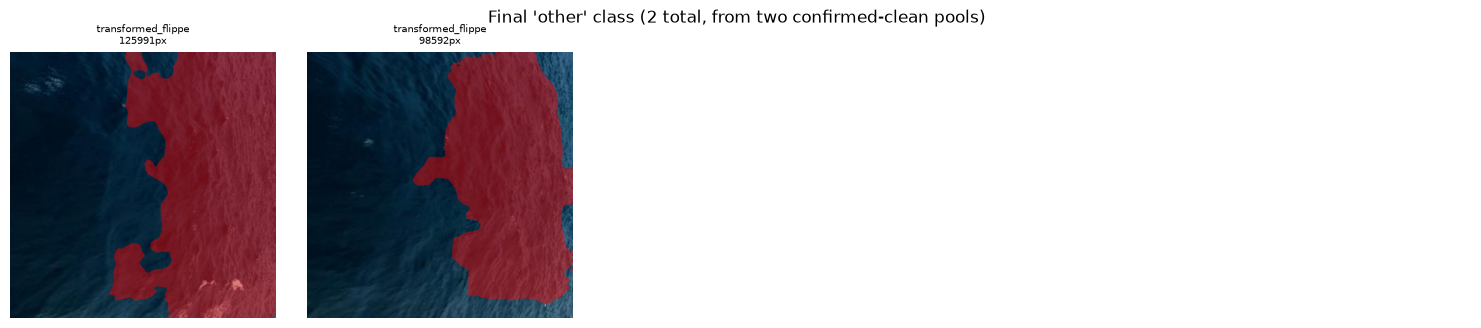

In [31]:
# --- Visualize the full combined 'other' set for a final spot-check ---

n_cols = 5
n_rows = (len(all_other_candidates) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3, n_rows * 3.3))
axes = np.atleast_2d(axes)

for idx in range(n_rows * n_cols):
    ax = axes[idx // n_cols][idx % n_cols]
    if idx < len(all_other_candidates):
        r = all_other_candidates[idx]
        ax.imshow(r["crop"])
        red_overlay = np.zeros((*r["stage2_mask"].shape, 4))
        red_overlay[r["stage2_mask"] == 1] = [1, 0, 0, 0.45]
        ax.imshow(red_overlay)
        ax.set_title(f"{Path(r['path']).name[:18]}\n{r['n_flagged_px_stage2']}px", fontsize=7)
    ax.axis("off")

plt.suptitle(f"Final 'other' class ({len(all_other_candidates)} total, from two confirmed-clean pools)")
plt.tight_layout()

grid_path = OTHER_CLASS_DIR / "_review_grid_combined.png"
plt.savefig(grid_path, dpi=120, bbox_inches="tight")
print(f"Saved combined review grid to: {grid_path.resolve()}")
plt.show()